[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/06.%20Advanced%20Logistic%20Regression/ch06_advanced_logistic_regression.ipynb)

# Chapter 6: Advanced Logistic Regression and Extensions

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 6, pp. 146–179

**What you will learn in this chapter:**
- How logistic regression turns a linear score into a class probability (sigmoid, log-odds, maximum likelihood)
- How to extend it to more than two classes: one-vs-rest (OvR) and multinomial (softmax)
- How L2 (Ridge) and L1 (Lasso) regularization work in logistic regression, and what the parameter `C` controls
- How to handle multilabel problems (several labels per sample) with one classifier per label
- How to evaluate a classifier: accuracy, confusion matrix, precision, recall, F1, ROC curve and AUC
- Practical exercises: regularized models, multiclass evaluation and decision-boundary visualisation

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Overview | $P(Y{=}1\mid X)=\sigma(\beta_0+\beta^\top x)$, fitted by maximum likelihood | `LogisticRegression` |
| Multiclass | OvR (one binary model per class) vs multinomial (softmax over all classes) | `OneVsRestClassifier`, `LogisticRegression` |
| Regularization | Penalise large coefficients; `C` = inverse strength | `penalty` / `l1_ratio`, `C` |
| Multilabel | Several labels per sample; train one binary model per label | `make_multilabel_classification`, `MultiOutputClassifier` |
| Evaluation | Accuracy, precision, recall, F1, ROC-AUC | `classification_report`, `roc_curve`, `auc` |
| Practical exercises | Regularized, multiclass and decision-boundary exercises | — |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, a verification against the numbers printed in the book, and a *Theory* cell.
Cells marked **Extension** are not in the book's code. Places where the book's text or code is inaccurate, or no longer runs on current scikit-learn, are flagged with **Book correction** (collected again at the end).
The book's snippets omit some imports (`matplotlib`, `seaborn`, `display`); they are added here.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

print("scikit-learn version:", sklearn.__version__)
print("NumPy version       :", np.__version__)

scikit-learn version: 1.9.1
NumPy version       : 2.5.3


## 1. Overview of logistic regression

**Summary.** Logistic regression is the standard method for **binary classification**. Unlike linear regression (which predicts a number), it predicts the **probability** that a point belongs to the positive class,
by passing a linear combination of the features through the **logistic (sigmoid) function**:
$$P(Y=1\mid X)=\frac{1}{1+e^{-(\beta_0+\beta_1X_1+\beta_2X_2+\dots+\beta_nX_n)}}$$
The output is always between 0 and 1. Observations are classified by a threshold, commonly **0.5**: probability above 0.5 → class 1, otherwise class 0. The coefficients are estimated by **maximum likelihood estimation (MLE)**.

> **Book correction (typo).** The book prints the exponent as $\beta_0+\beta_1X_1+\beta_2X_2\dots\beta_n\mathbf{+}X_n$ — the last term should be a *product* $\beta_nX_n$, as written above.

### Getting ready — the Breast Cancer dataset
569 tumours, 30 numeric measurements. In scikit-learn the target is **0 = malignant, 1 = benign** (so class 1, "benign", is the *positive* class in all the metrics below).

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    classification_report
)
import pandas as pd

data = load_breast_cancer()
X = data.data
y = data.target

# Convert to a DataFrame for easier manipulation (optional)
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(
    df[data.feature_names], df['target'],
    test_size=0.2, random_state=2024
)
print(X_train.shape, X_test.shape, "| classes:", dict(zip(data.target_names, np.bincount(y))))

(455, 30) (114, 30) | classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


### How to do it…

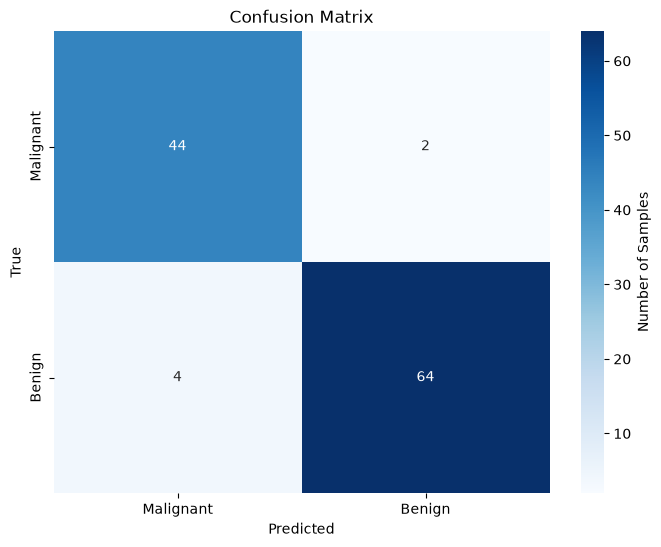

Accuracy: 0.95


Classification Report:


,precision,recall,f1-score,support
Malignant,0.917,0.957,0.936,46
Benign,0.970,0.941,0.955,68
accuracy,0.947,0.947,0.947,1
macro avg,0.943,0.949,0.946,114
weighted avg,0.948,0.947,0.948,114


In [3]:
model = LogisticRegression(max_iter=10000) # Increase max_iter if convergence issues occur
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

class_names = ['Malignant', 'Benign']
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

report_dict = classification_report(
    y_test, y_pred,
    target_names=class_names,
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose()
styled_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f'Accuracy: {accuracy:.2f}\n')
print("\nClassification Report:")
display(styled_df)

**Verification against the book:** it prints `Accuracy: 0.95` — ✔ matches (0.9474 rounds to 0.95), and its Figure 6.1/6.2 show a confusion matrix with very few mistakes.

> **Note on the `accuracy` row (a display artefact in the book's tables).** In `classification_report(..., output_dict=True)` the entry `'accuracy'` is a *single number*, not a dict like the other rows. When it is turned into a DataFrame, that number is
> **broadcast into every column** — so the accuracy appears under `precision`, `recall`, `f1-score` **and `support`**. The book's `support` format (`'{:.0f}'`) then rounds 0.98 to **`1`**, which is why its tables show a support of 1 for that row.
> It is *not* a sample count. (The real number of test samples is the support of the `macro avg` / `weighted avg` rows: 171 here.) Check below:

**The book's question:** "a model's accuracy isn't always the best metric (especially when predicting whether a person has breast cancer). What other metric might be better?"
**Answer: recall (sensitivity) of the malignant class.** A *false negative* (a malignant tumour called benign) is far more costly than a false alarm, so what matters is the share of true malignant cases the model catches:

In [4]:
print("the 'accuracy' row of the report DataFrame:", report_df.loc["accuracy"].round(3).to_dict(), "-> support formatted with '{:.0f}' shows:", "{:.0f}".format(report_df.loc["accuracy", "support"]))
tn, fp, fn, tp = cm.ravel()      # rows = true (0 = malignant, 1 = benign), columns = predicted
print(f"malignant recall (caught {tn} of {tn + fp}) = {tn / (tn + fp):.3f}   <- the metric that matters for screening")
print(f"malignant missed (called benign)       = {fp}")
print(f"overall accuracy                       = {accuracy:.3f}")

the 'accuracy' row of the report DataFrame: {'precision': 0.947, 'recall': 0.947, 'f1-score': 0.947, 'support': 0.947} -> support formatted with '{:.0f}' shows: 1
malignant recall (caught 44 of 46) = 0.957   <- the metric that matters for screening
malignant missed (called benign)       = 2
overall accuracy                       = 0.947


### How it works…
The model estimates probabilities through a linear combination of the features transformed by the logistic function; each coefficient says how a feature shifts the **log-odds** of the positive class.
The decision boundary is linear in the features (a hyperplane where the log-odds equal 0).

**Log-odds (the book's box).** The *odds* of an event are $\frac{p}{1-p}$; the *log-odds* (logit) are $\ln\frac{p}{1-p}$. The logit maps a probability in $(0,1)$ to the whole real line, which is why a *linear* model can be put on it:
$$\ln\frac{p}{1-p}=\beta_0+\beta_1x_1+\dots+\beta_nx_n\quad\Longleftrightarrow\quad p=\sigma(\beta_0+\beta^\top x).$$

**Extension — the sigmoid, the logit, and the model's probabilities computed by hand:**

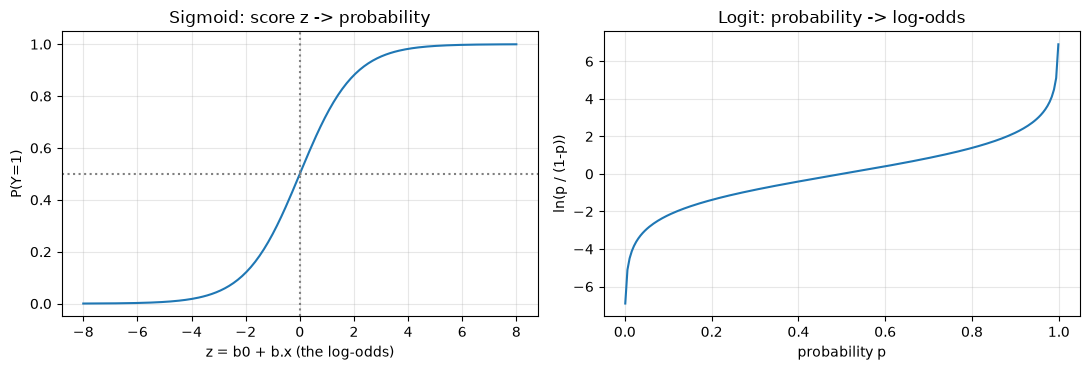

max |manual P(benign) - predict_proba| = 2.7755575615628914e-17
predict() == (probability > 0.5): True | equivalently (z > 0): True


In [5]:
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))
p = np.linspace(0.001, 0.999, 200)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(z, sigmoid); ax[0].axhline(.5, c="grey", ls=":"); ax[0].axvline(0, c="grey", ls=":")
ax[0].set_title("Sigmoid: score z -> probability"); ax[0].set_xlabel("z = b0 + b.x (the log-odds)"); ax[0].set_ylabel("P(Y=1)")
ax[1].plot(p, np.log(p / (1 - p))); ax[1].set_title("Logit: probability -> log-odds"); ax[1].set_xlabel("probability p"); ax[1].set_ylabel("ln(p / (1-p))")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# probabilities by hand from the fitted coefficients
z_test = X_test.values @ model.coef_[0] + model.intercept_[0]
p_manual = 1 / (1 + np.exp(-z_test))
print("max |manual P(benign) - predict_proba| =", np.abs(p_manual - model.predict_proba(X_test)[:, 1]).max())
print("predict() == (probability > 0.5):", ((p_manual > 0.5).astype(int) == y_pred).all(), "| equivalently (z > 0):", ((z_test > 0).astype(int) == y_pred).all())

The model's probability is exactly the sigmoid of the linear score, and the 0.5 threshold is the same as "score > 0" (log-odds above 0).

**Extension — maximum likelihood = minimising the log-loss.** The coefficients are chosen to maximise the likelihood of the observed labels, i.e. to minimise
$$\text{log-loss}=-\frac1n\sum_i\big[y_i\ln p_i+(1-y_i)\ln(1-p_i)\big].$$

In [6]:
from sklearn.metrics import log_loss
p_tr = model.predict_proba(X_train)[:, 1]
manual = -np.mean(y_train * np.log(p_tr) + (1 - y_train) * np.log(1 - p_tr))
print("training log-loss: manual", round(manual, 5), "| sklearn", round(log_loss(y_train, p_tr), 5))
print("test log-loss     :", round(log_loss(y_test, model.predict_proba(X_test)[:, 1]), 5))

training log-loss: manual 0.07935 | sklearn 0.07935
test log-loss     : 0.16896


**Extension — reading coefficients as odds ratios.** $e^{\beta_j}$ is the factor by which the *odds* of "benign" are multiplied when feature $j$ increases by one unit (others fixed). Raw coefficients depend on each feature's unit, so for a fair comparison
I use a model fitted on **standardised** features (then "one unit" = one standard deviation):

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

std_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000)).fit(X_train, y_train)
coefs = pd.Series(std_model[-1].coef_[0], index=data.feature_names)
odds = pd.DataFrame({"coef (per 1 SD)": coefs, "odds ratio exp(coef)": np.exp(coefs)}).reindex(coefs.abs().sort_values(ascending=False).index)
print("test accuracy of the standardised model:", round(std_model.score(X_test, y_test), 4))
display(odds.head(8).round(3))

test accuracy of the standardised model: 0.9825


,coef (per 1 SD),odds ratio exp(coef)
worst texture,-1.336,0.263
radius error,-1.265,0.282
worst radius,-1.027,0.358
worst area,-0.933,0.393
mean concave points,-0.924,0.397
mean concavity,-0.847,0.429
worst concavity,-0.846,0.429
worst concave points,-0.845,0.430


A negative coefficient (odds ratio below 1) means a larger value makes **benign less likely** (malignant more likely): e.g. larger `worst radius`, `worst texture` or `radius error` push towards malignant. (Highly correlated features share the effect, so individual coefficients should be read with care — Chapter 5.)

### Evaluating model performance (book)
* **Accuracy** — proportion of correct predictions. * **Confusion matrix** — TP, TN, FP, FN. * **Precision and recall** — quality on the positive class. * **ROC curves** — performance across *all* thresholds (Section 5).

### Theory
* **Model:** $\text{logit}(p)=\beta_0+\beta^\top x$. It is a *generalized linear model* with a Bernoulli outcome and the logit link.
* **Training:** there is no closed form (unlike OLS); the likelihood is maximised iteratively (solvers such as `lbfgs`, `liblinear`, `newton-cg`, `saga`). The log-loss is convex, so there is one global optimum. With perfectly separable classes the unregularised
  coefficients diverge to infinity — one reason scikit-learn applies L2 regularisation **by default** (`C=1.0`).
* **Linear boundary:** $\beta_0+\beta^\top x=0$. Non-linear boundaries need feature engineering (polynomial/spline features, Chapter 5) or other models (Chapters 7–8).
* **Threshold:** 0.5 is a default, not a law. Lower it when missing a positive is costly (here: missing a malignant tumour is costly, so predicting "malignant" whenever $P(\text{benign})$ is below, say, 0.7 raises malignant recall at the price of more false alarms — see Section 5).
* **Assumptions:** independent observations, linear relationship between features and log-odds, little multicollinearity, enough samples per class.

### Hands-on workflow (from the book)
Load the data → (no missing values here) → `LogisticRegression` → `fit` → `predict` → accuracy, confusion matrix, precision/recall/F1 → plot predicted probabilities against actual outcomes or ROC curves. (The probability and ROC plots are in the extension above and Section 5.)

## 2. Multiclass classification techniques

**Summary.** Logistic regression extends to more than two classes in two ways:
* **One-vs-Rest (OvR / one-vs-all):** train one binary classifier per class ("this class vs all others"); predict the class whose classifier is most confident.
* **Multinomial (softmax regression):** model all classes jointly with a **softmax** function so the probabilities of all classes sum to 1; one set of coefficients per class is fitted simultaneously.

### Getting ready — the Iris dataset (3 classes)

In [8]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import DecisionBoundaryDisplay
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)
print(X_train.shape, X_test.shape, "| test class counts:", np.bincount(y_test))

(105, 4) (45, 4) | test class counts: [18 12 15]


### How to do it… — and what happens to the book's code today
The book builds the OvR model with `LogisticRegression(solver='liblinear')` and the multinomial model with `LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)`. Run both exactly as printed:

In [9]:
for name, kwargs in {
    "book's OvR model        ": dict(solver='liblinear'),
    "book's multinomial model": dict(multi_class='multinomial', solver='lbfgs', max_iter=1000),
}.items():
    try:
        LogisticRegression(**kwargs).fit(X_train, y_train)
        print(name, "-> runs")
    except Exception as e:
        print(name, "->", type(e).__name__ + ":", str(e).splitlines()[0][:150])

book's OvR model         -> ValueError: The 'liblinear' solver does not support multiclass classification (n_classes >= 3). Either use another solver or wrap the estimator in a OneVsRestClas
book's multinomial model -> TypeError: LogisticRegression.__init__() got an unexpected keyword argument 'multi_class'


> **Book correction (code no longer runs).** The book notes that "after version 1.7 the `multi_class` argument will be removed and multinomial will always be used for 3+ classes". That has happened: in current scikit-learn
> * `multi_class=` no longer exists (`TypeError`), and
> * the `liblinear` solver refuses multiclass problems outright (`ValueError`) — it only supports binary problems.
>
> The equivalents: **multinomial** is simply the default (`LogisticRegression(solver='lbfgs')`), and **OvR** is obtained explicitly by wrapping a binary logistic regression in `OneVsRestClassifier`. This reproduces the book's results (below).

In [10]:
from sklearn.multiclass import OneVsRestClassifier

# 1. OvR: one binary logistic regression per class (liblinear is fine because each sub-problem is binary)
ovr_model = OneVsRestClassifier(LogisticRegression(solver='liblinear'))
ovr_model.fit(X_train, y_train)

# 2. Multinomial: the default behaviour for 3+ classes
multinomial_model = LogisticRegression(solver='lbfgs', max_iter=1000)
multinomial_model.fit(X_train, y_train)

y_pred_ovr = ovr_model.predict(X_test)
y_pred_multinomial = multinomial_model.predict(X_test)

def styled_report(y_true, y_hat):
    rep = pd.DataFrame(classification_report(y_true, y_hat, output_dict=True)).transpose()
    return (rep.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
            .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

accuracy_ovr = accuracy_score(y_test, y_pred_ovr)
print("One-vs-Rest (OvR) Logistic Regression: accuracy =", round(accuracy_ovr, 4))
display(styled_report(y_test, y_pred_ovr))

accuracy_multinomial = accuracy_score(y_test, y_pred_multinomial)
print("Multinomial Logistic Regression: accuracy =", round(accuracy_multinomial, 4))
display(styled_report(y_test, y_pred_multinomial))

One-vs-Rest (OvR) Logistic Regression: accuracy = 0.9556


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.917,0.917,0.917,12
2,0.933,0.933,0.933,15
accuracy,0.956,0.956,0.956,1
macro avg,0.950,0.950,0.950,45
weighted avg,0.956,0.956,0.956,45


Multinomial Logistic Regression: accuracy = 0.9333


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.846,0.917,0.880,12
2,0.929,0.867,0.897,15
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.928,0.926,45
weighted avg,0.935,0.933,0.934,45


**Verification against the book:** Figure 6.3 (OvR) shows accuracy **0.956** with per-class precision/recall 1.000 / 0.917 / 0.933, and Figure 6.4 (multinomial) shows accuracy **0.933** (class 1: precision 0.846, recall 0.917; class 2: 0.929 / 0.867).
Both are reproduced above ✔ (supports 18 / 12 / 15).

> **Book corrections for the text of this recipe.**
> 1. "Macro **accuracy** is a label-wise unweighted average" — it is the **macro average of precision, recall and F1** (the report has no macro *accuracy*); the *weighted* average weights each class by its support.
> 2. "Even though we are using multinomial classification for a **binary** classification problem…" — the Iris problem has **three** classes, and the point is the difference between the strategies: OvR fits one *binary* model per class and compares their scores, while multinomial predicts a probability for *every* class jointly.

### How it works…
**OvR.** For each class $k$ a binary logistic regression separates class $k$ (positive) from everything else; prediction picks the class with the highest score. The per-class probabilities are *not* constrained to sum to 1 (scikit-learn normalises them afterwards).
**Multinomial (softmax).** One coefficient vector $\beta_k$ per class, fitted jointly by minimising the cross-entropy:
$$P(Y=k\mid x)=\frac{e^{\beta_{k0}+\beta_k^\top x}}{\sum_{j}e^{\beta_{j0}+\beta_j^\top x}}$$
Better suited when classes are **mutually exclusive**. Both are verified by hand below.

In [11]:
# softmax by hand for the multinomial model
scores = X_test @ multinomial_model.coef_.T + multinomial_model.intercept_
softmax = np.exp(scores - scores.max(axis=1, keepdims=True)); softmax /= softmax.sum(axis=1, keepdims=True)
print("softmax by hand == predict_proba:", np.allclose(softmax, multinomial_model.predict_proba(X_test)))
print("coef_ shape (one row per class):", multinomial_model.coef_.shape)

# OvR: one binary model per class, scores combined
print("\nOvR estimators:", len(ovr_model.estimators_), "binary models, classes:", ovr_model.classes_)
raw = np.column_stack([est.predict_proba(X_test)[:, 1] for est in ovr_model.estimators_])
print("raw one-vs-rest probabilities sum to 1?  ->", np.allclose(raw.sum(axis=1), 1), "(first rows sum:", raw.sum(axis=1)[:3].round(2), ")")
print("OvR predict_proba sums to 1 (normalised):", np.allclose(ovr_model.predict_proba(X_test).sum(axis=1), 1))
print("\nTest points where the two strategies disagree:", int((y_pred_ovr != y_pred_multinomial).sum()), "of", len(y_test))

softmax by hand == predict_proba: True
coef_ shape (one row per class): (3, 4)

OvR estimators: 3 binary models, classes: [0 1 2]
raw one-vs-rest probabilities sum to 1?  -> False (first rows sum: [1.08 1.14 0.71] )
OvR predict_proba sums to 1 (normalised): True

Test points where the two strategies disagree: 3 of 45


### Key considerations (book)
* **Solver selection:** `liblinear` for OvR (binary sub-problems); `lbfgs` or `newton-cg` for multinomial.
* **Regularization:** multiclass logistic regression benefits from it just like the binary case (Section 3).
* **Preprocessing:** scale numeric features — **Extension:** effect of scaling inside a leak-free pipeline on a harder dataset (Wine, 3 classes, very different feature scales):

In [12]:
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score, StratifiedKFold

Xw, yw = load_wine(return_X_y=True)
cv = StratifiedKFold(5, shuffle=True, random_state=2024)
rows = {}
for name, est in {
    "multinomial, raw features": LogisticRegression(max_iter=5000),
    "multinomial, standardised": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "OvR, raw features": OneVsRestClassifier(LogisticRegression(solver="liblinear", max_iter=5000)),
    "OvR, standardised": make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(solver="liblinear"))),
}.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        s = cross_val_score(est, Xw, yw, cv=cv); rows[name] = {"mean CV accuracy": s.mean(), "sd": s.std()}
pd.DataFrame(rows).T.round(3)

,mean CV accuracy,sd
"multinomial, raw features",0.961,0.014
"multinomial, standardised",0.983,0.014
"OvR, raw features",0.949,0.033
"OvR, standardised",0.989,0.014


Scaling matters: it speeds up convergence and (with regularisation, which is on by default) makes the penalty treat all features fairly. OvR and multinomial perform about the same here; the choice matters more for probability quality than for accuracy.

### There's more… the pairplot
The book uses a seaborn pairplot to see how well the features separate the classes.

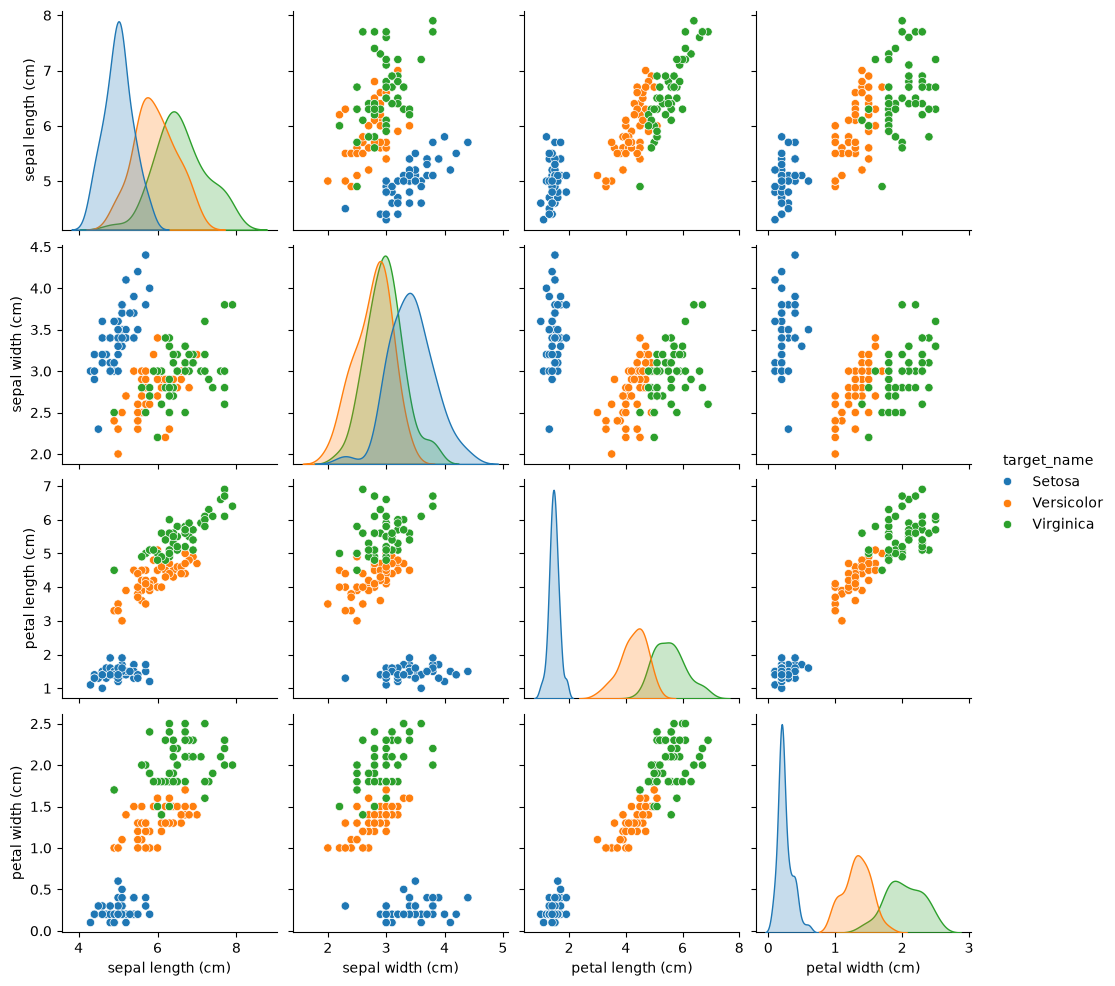

In [13]:
target_names = {0: 'Setosa',
                1: 'Versicolor',
                2: 'Virginica'}
df['target_name'] = df['target'].map(target_names)
sns.pairplot(df.drop(columns="target"), hue='target_name', diag_kind='kde')
plt.show()

The book says petal length and petal width are "distributed with a high kurtosis (e.g., concentrated at a small set of values, creating a highly narrow, peaked distribution)", which "confirms these features as highly valuable". Check the kurtosis:

In [14]:
from scipy.stats import kurtosis
pd.DataFrame({"excess kurtosis": {f: kurtosis(df[f]) for f in feature_names}}).round(2)

,excess kurtosis
sepal length (cm),-0.57
sepal width (cm),0.18
petal length (cm),-1.40
petal width (cm),-1.34


> **Book correction.** Petal length and width do **not** have high (peaked) kurtosis: their *excess* kurtosis is strongly **negative** (≈ −1.4 and −1.3; a normal distribution is 0), i.e. flat/bimodal distributions — and the *diagonal* KDE panels
> of the pairplot (one KDE curve per species) show why: setosa's curve sits in a tight cluster far from the other two, so all species pooled form a flat, two-hump distribution (negative excess kurtosis). That separation (the species' petal measurements barely overlap, visible in the off-diagonal scatterplots)
> is what makes these features valuable, not "peakedness".

### Hands-on workflow (book): step 9 — decision boundaries for OvR and multinomial
Decision boundaries can only be drawn in 2-D, so both models are refitted on the two petal features:

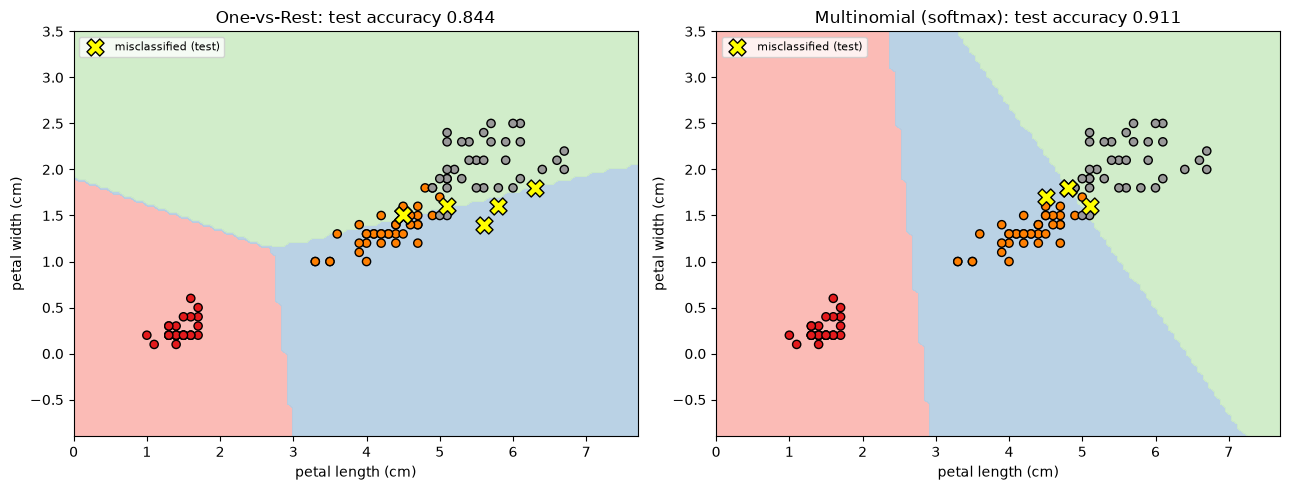

In [15]:
feat = [2, 3]    # petal length, petal width
Xp_train, Xp_test = X_train[:, feat], X_test[:, feat]
ovr2 = OneVsRestClassifier(LogisticRegression(solver='liblinear')).fit(Xp_train, y_train)
mult2 = LogisticRegression(solver='lbfgs', max_iter=1000).fit(Xp_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, m) in zip(axes, {"One-vs-Rest": ovr2, "Multinomial (softmax)": mult2}.items()):
    pastel = ["#fbb4ae", "#b3cde3", "#ccebc5"]            # region colours for the three classes
    try:                                                   # newer scikit-learn: multiclass_colors
        DecisionBoundaryDisplay.from_estimator(m, Xp_train, response_method="predict", multiclass_colors=pastel, alpha=.9, ax=ax,
                                               xlabel=iris.feature_names[feat[0]], ylabel=iris.feature_names[feat[1]])
    except TypeError:                                      # older versions: cmap
        from matplotlib.colors import ListedColormap
        DecisionBoundaryDisplay.from_estimator(m, Xp_train, response_method="predict", cmap=ListedColormap(pastel), alpha=.9, ax=ax,
                                               xlabel=iris.feature_names[feat[0]], ylabel=iris.feature_names[feat[1]])
    ax.scatter(Xp_train[:, 0], Xp_train[:, 1], c=y_train, cmap="Set1", edgecolor="k", s=35)
    wrong = m.predict(Xp_test) != y_test
    ax.scatter(Xp_test[wrong, 0], Xp_test[wrong, 1], marker="X", c="yellow", edgecolor="k", s=150, label="misclassified (test)")
    ax.set_title(f"{name}: test accuracy {m.score(Xp_test, y_test):.3f}")
    if wrong.any(): ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

Both give **linear boundaries** (straight lines between regions): logistic regression is a linear classifier even with three classes. The versicolor/virginica border is where mistakes happen. OvR draws each class's region from its own one-vs-rest line
(which can leave awkward corners when lines cross), while multinomial's regions come from comparing all scores together.

### Theory
* **OvR:** $K$ binary models; cheap and parallel; the scores of separately trained models are not calibrated against each other; can struggle when classes overlap strongly.
* **Multinomial:** one joint model; *calibrated* probabilities that sum to 1; the standard modern default. The binary logistic model is the $K=2$ special case of softmax (the redundancy is removed by fixing one class's coefficients to 0).
* **Loss:** cross-entropy $-\frac1n\sum_i\ln P(y_i\mid x_i)$ for multinomial vs $K$ separate log-losses for OvR.
* **Macro vs weighted averages:** macro treats every class equally (good to expose poor performance on rare classes); weighted reflects overall performance dominated by large classes.
* **Solvers:** `lbfgs` (default, good for small/medium data, multinomial), `newton-cg`, `saga` (large data, supports all penalties), `liblinear` (binary only, L1 and L2).

### Hands-on workflow (from the book)
Load Iris → `LogisticRegression` → implement OvR and multinomial → compare with accuracy and the classification report → pairplot → decision boundaries (all done above).

## 3. Regularization in logistic regression

**Summary.** Regularization penalises large coefficients to prevent overfitting. As in Chapter 5 there is an **L2 (Ridge)** and an **L1 (Lasso)** version; but in `LogisticRegression` the strength is set with **`C`, the *inverse* of the regularization strength**:
smaller `C` → stronger regularization. (L2 is on by default with `C=1.0`.)

### Getting ready — Breast Cancer again, split then scaled

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit on the training set only ...
X_test = scaler.transform(X_test)         # ... then apply to the test set (no leakage)

### How to do it…
Ridge (L2) and Lasso (L1) logistic regression with `C=0.1`.

> **Book correction (deprecation).** The book selects the penalty with `penalty='l2'` / `penalty='l1'`. Since **scikit-learn 1.8** the `penalty` parameter is deprecated (to be removed in 1.10) in favour of `l1_ratio`
> (`0` = L2, `1` = L1, in between = ElasticNet). The book's code still *works* — it emits a `FutureWarning` and, for the L1 model, an extra `UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0` (the explicit `penalty` prevails over the default
> `l1_ratio=0.0`, so the results are the book's). Both warnings are hidden below. The modern spelling is **equivalent**: identical L2 coefficients, and for L1 the same predictions and the same sparsity, with coefficients that agree only approximately
> (differences of order 10⁻³–10⁻², varying from run to run, because liblinear's L1 solver is randomised when `random_state` is not set) — shown at the end of the next cell.

In [17]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # hides: 'penalty' is deprecated (FutureWarning) and, for L1, "Inconsistent values: penalty=l1 with l1_ratio=0.0" (UserWarning)
    ridge_model = LogisticRegression(
        penalty='l2', solver='liblinear', C=0.1)
    ridge_model.fit(X_train, y_train)
    lasso_model = LogisticRegression(
        penalty='l1', solver='liblinear', C=0.1)
    lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

accuracy_ridge = accuracy_score(y_test, y_pred_ridge)
report_ridge = pd.DataFrame(classification_report(
    y_test, y_pred_ridge, output_dict=True)).transpose()
print("Ridge (L2) Regularized Logistic Regression: accuracy =", round(accuracy_ridge, 4))
display(report_ridge.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
report_lasso = pd.DataFrame(classification_report(
    y_test, y_pred_lasso, output_dict=True)).transpose()
print("Lasso (L1) Regularized Logistic Regression: accuracy =", round(accuracy_lasso, 4))
display(report_lasso.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

# the modern, non-deprecated spelling (scikit-learn >= 1.8): l1_ratio=0 -> L2, l1_ratio=1 -> L1
try:
    r2 = LogisticRegression(l1_ratio=0, solver='liblinear', C=0.1).fit(X_train, y_train)
    r1 = LogisticRegression(l1_ratio=1, solver='liblinear', C=0.1).fit(X_train, y_train)
    print("\nmodern l1_ratio API vs the book's penalty=...")
    print("  L2: max |coef difference| =", np.abs(r2.coef_ - ridge_model.coef_).max(), "| same predictions:", (r2.predict(X_test) == y_pred_ridge).all())
    print("  L1: max |coef difference| =", round(np.abs(r1.coef_ - lasso_model.coef_).max(), 5), "| same predictions:", (r1.predict(X_test) == y_pred_lasso).all(),
          "| same non-zero count:", int((r1.coef_ != 0).sum()) == int((lasso_model.coef_ != 0).sum()))
except TypeError:
    print("\n(this scikit-learn version predates l1_ratio for liblinear; use penalty=... as in the book)")

Ridge (L2) Regularized Logistic Regression: accuracy = 0.9825


,precision,recall,f1-score,support
0,0.985,0.970,0.977,67
1,0.981,0.990,0.986,104
accuracy,0.982,0.982,0.982,1
macro avg,0.983,0.980,0.982,171
weighted avg,0.982,0.982,0.982,171


Lasso (L1) Regularized Logistic Regression: accuracy = 0.9649


,precision,recall,f1-score,support
0,0.930,0.985,0.957,67
1,0.990,0.952,0.971,104
accuracy,0.965,0.965,0.965,1
macro avg,0.960,0.968,0.964,171
weighted avg,0.966,0.965,0.965,171



modern l1_ratio API vs the book's penalty=...
  L2: max |coef difference| = 0.0 | same predictions: True
  L1: max |coef difference| = 0.00193 | same predictions: True | same non-zero count: True


**Verification against the book:** Figure 6.6 (Ridge) reports accuracy 0.982 (class 0: precision 0.985 / recall 0.970; class 1: 0.981 / 0.990), and Figure 6.7 (Lasso) accuracy 0.965 (class 0: 0.930 / 0.985; class 1: 0.990 / 0.952). All reproduced above ✔ (support 67 / 104).

The book concludes: "Lasso has a slightly lower accuracy … ridge outperforms in precision while Lasso outperforms in recall". **That is only true for class 0 (malignant):** there Ridge's precision is higher (0.985 vs 0.930) and Lasso's recall is higher (0.985 vs 0.970).
For class 1 (benign) it is the **reverse** (Lasso's precision 0.990 > Ridge's 0.981; Ridge's recall 0.990 > Lasso's 0.952). Precision and recall are *per class*, so a statement like this must name the class; for the overall comparison, Ridge is better here (accuracy 0.982 vs 0.965 — 2 more mistakes out of 171).

### How it works…
Regularization adds a penalty to the loss. In scikit-learn the objective of `LogisticRegression` is
$$\min_{\beta}\ \underbrace{\tfrac12\lVert\beta\rVert_2^2}_{\text{L2 penalty}}+C\sum_{i=1}^n\ \text{log-loss}_i\qquad\text{(L1: }\lVert\beta\rVert_1\text{ replaces the first term)}$$
so a large `C` means the data term dominates (weak regularisation) and a small `C` means the penalty dominates. `C` is roughly $1/\alpha$ in Chapter 5's notation.
* **Ridge (L2):** shrinks coefficients towards 0 but rarely sets them exactly to 0. * **Lasso (L1):** can set some exactly to 0 — feature selection.

In [18]:
print("non-zero coefficients out of 30 -> Ridge:", int((ridge_model.coef_ != 0).sum()), "| Lasso:", int((lasso_model.coef_ != 0).sum()))
print("features kept by Lasso (C=0.1):", [n for n, c in zip(feature_names, lasso_model.coef_[0]) if c != 0])
print("sum of squared coefficients  -> Ridge: %.2f | Lasso: %.2f" % ((ridge_model.coef_ ** 2).sum(), (lasso_model.coef_ ** 2).sum()))

non-zero coefficients out of 30 -> Ridge: 30 | Lasso: 7
features kept by Lasso (C=0.1): [np.str_('mean concave points'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst smoothness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry')]
sum of squared coefficients  -> Ridge: 2.95 | Lasso: 5.48


Lasso keeps only 7 of the 30 features and still reaches 96.5 % accuracy — a much sparser, easier-to-explain model.

### Key considerations (book)
* **Solver selection:** `liblinear` supports both L1 and L2 on small datasets; **`saga`** is the choice for larger datasets (it also supports ElasticNet).
* **Data scaling:** regularization is sensitive to feature scale, so scale first (done above).
* **Hyper-parameter tuning:** tune `C` with grid/random search — **Extension: `LogisticRegressionCV`** does it with built-in cross-validation, in a leak-free pipeline:

In [19]:
from sklearn.linear_model import LogisticRegressionCV

Xtr_raw, Xte_raw, ytr_raw, yte_raw = train_test_split(X, y, test_size=0.3, random_state=2024)
for label, kw in {"L2": dict(l1_ratios=(0,), solver="liblinear"), "L1": dict(l1_ratios=(1,), solver="liblinear")}.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                 # LogisticRegressionCV announces a coming change to its fitted attributes
        try:
            cvm = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-3, 2, 20), cv=5, scoring="accuracy", max_iter=5000, **kw)).fit(Xtr_raw, ytr_raw)
        except TypeError:                               # older scikit-learn: select the penalty with `penalty=`
            cvm = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-3, 2, 20), cv=5, scoring="accuracy", max_iter=5000,
                                                                       penalty=label.lower(), solver="liblinear")).fit(Xtr_raw, ytr_raw)
    est = cvm[-1]
    print(f"{label}: best C by 5-fold CV = {est.C_[0]:.4g} | test accuracy = {cvm.score(Xte_raw, yte_raw):.4f} | non-zero coefficients = {int((est.coef_ != 0).sum())}")

L2: best C by 5-fold CV = 0.2336 | test accuracy = 0.9766 | non-zero coefficients = 30


L1: best C by 5-fold CV = 0.2336 | test accuracy = 0.9766 | non-zero coefficients = 9


### There's more… coefficients as a function of `C`
The book plots every coefficient for `C` from 0.0001 to 1000, for Ridge then Lasso (Figures 6.8 and 6.9).

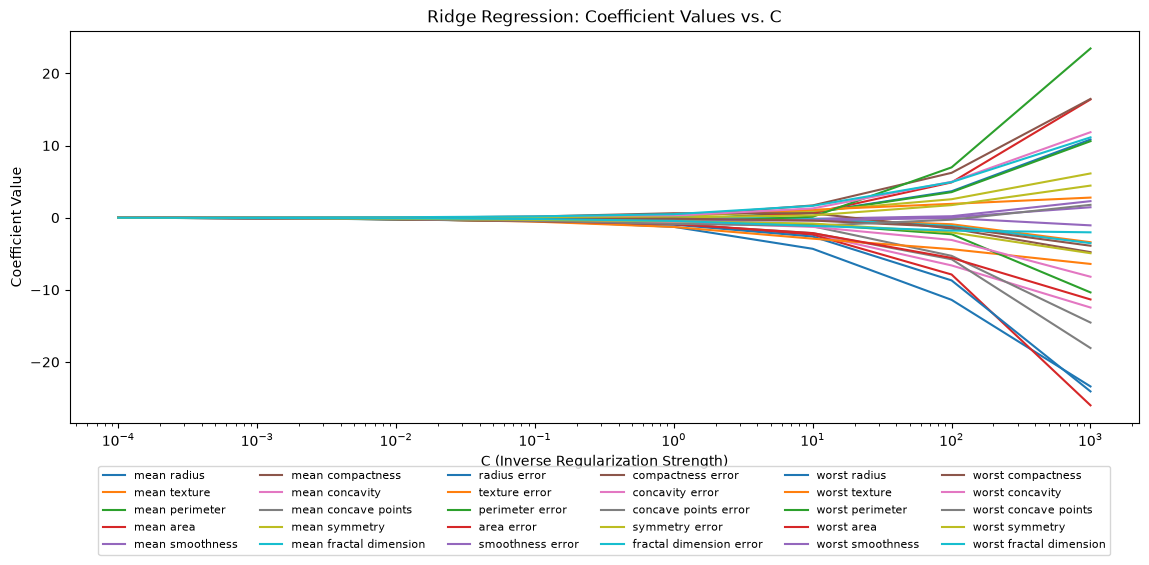

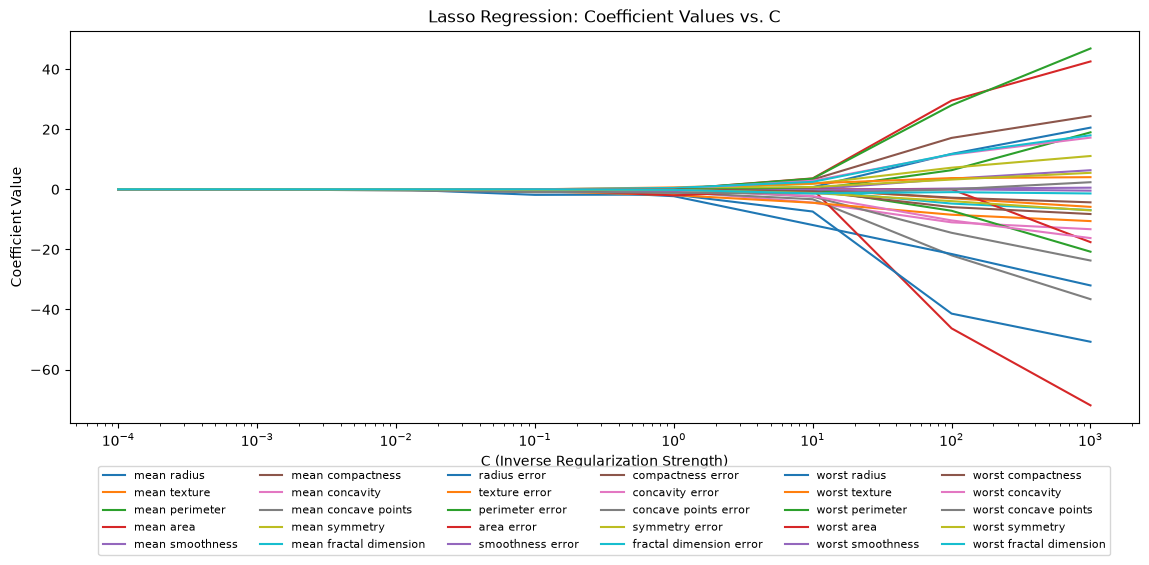

In [20]:
C_values = np.array(
    [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])

def coef_path(penalty):
    out = []
    for C in C_values:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = LogisticRegression(penalty=penalty, solver='liblinear', C=C)
            m.fit(X_train, y_train)
        out.append(m.coef_[0])
    return out

for penalty, title in (('l2', 'Ridge'), ('l1', 'Lasso')):
    coefs = coef_path(penalty)
    plt.figure(figsize=(12, 6))
    for i in range(X.shape[1]):
        plt.plot(
            C_values, [coef[i] for coef in coefs],
            label=feature_names[i]
        )
    plt.xscale('log')
    plt.xlabel('C (Inverse Regularization Strength)')
    plt.ylabel('Coefficient Value')
    plt.title(f'{title} Regression: Coefficient Values vs. C')
    plt.legend(
        bbox_to_anchor=(0.5, -0.35),
        ncol=6, loc='lower center', fontsize=8
    )
    plt.tight_layout()
    plt.show()

Reading the plots: on the **left** (small `C`, strong regularisation) all coefficients are near 0; moving **right** the coefficients grow. With **L2** they all rise smoothly and together; with **L1** coefficients stay *exactly* 0 over a wide range and enter the model one at a time —
a handful of features carry the signal first. At very large `C` (≥ 100) both models approach the unregularised solution and coefficients become large and unstable for correlated features (the breast-cancer measurements `radius`, `perimeter`, `area` are almost perfectly correlated).
Note the x-axis here is $C$ — the **opposite direction** from Chapter 5's $\alpha$ plots (where large $\alpha$ meant strong regularisation).

**Extension — the same information as numbers, and the accuracy it buys:**

In [21]:
rows = []
for C in C_values:
    row = {"C": C}
    for pen in ("l2", "l1"):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = LogisticRegression(penalty=pen, solver="liblinear", C=C).fit(X_train, y_train)
        row[f"{pen.upper()} non-zero"] = int((m.coef_ != 0).sum()); row[f"{pen.upper()} test acc"] = round(m.score(X_test, y_test), 3)
    rows.append(row)
pd.DataFrame(rows).set_index("C")

,L2 non-zero,L2 test acc,L1 non-zero,L1 test acc
C,,,,
0.0001,30,0.918,0,0.392
0.0010,30,0.936,0,0.392
0.0100,30,0.947,2,0.918
0.1000,30,0.982,7,0.965
1.0000,30,0.982,15,0.977
10.0000,30,0.977,23,0.965
100.0000,30,0.959,27,0.947
1000.0000,30,0.947,30,0.947


With L1, the number of non-zero coefficients grows from 0 (C = 0.0001–0.001) to 7 at the book's `C=0.1` and to all 30 for very large `C`; accuracy peaks at moderate `C` (≈ 0.98 for L2 at `C` 0.1–1, 0.977 for L1 at `C=1`) and does **not** keep improving with weaker
regularisation — the bias–variance trade-off of Chapter 5, with `C` as the dial. At the two smallest `C` the L1 model has *all coefficients and the intercept equal to 0* (liblinear penalises the intercept too), so it gives one constant prediction for everyone:
its accuracy of 0.392 is exactly the share of class 0 (malignant) in the test set (67 of 171) — i.e. it labels every case malignant, **not** the majority class. L2 at tiny `C` is also heavily shrunk but still ranks cases (accuracy 0.92).

### Theory
* **Why regularise logistic regression?** With many correlated features, or classes that are (nearly) linearly separable, maximum-likelihood coefficients become huge and unstable; the penalty keeps them finite and improves generalisation.
* **L2 vs L1:** same geometry as in Chapter 5 (sphere vs diamond constraint; L1 gives sparsity). L1 is a built-in feature selector; L2 handles correlated features more stably. **ElasticNet** mixes both (`l1_ratio` between 0 and 1, solver `saga`).
* **Bayesian view:** L2 ↔ Gaussian prior on the coefficients, L1 ↔ Laplace prior (MAP estimates).
* **Scaling matters** because the penalty is the same for every coefficient regardless of the feature's units.
* **Intercept:** not penalised (for `lbfgs`, `saga`; `liblinear` does penalise it — another reason solvers can give slightly different results).

### Hands-on workflow (from the book)
Load Breast Cancer → scale → fit Ridge and Lasso logistic regression → compare with accuracy and the classification report → plot coefficients against `C` (done above).

## 4. Multilabel classification concepts

**Summary.** In **multilabel** classification each sample can belong to **several classes at once** (a news article tagged *politics* **and** *economy*; an image tagged *beach*, *people*, *sunset*), unlike multiclass classification where each sample has exactly one class.
The simplest approach is **binary relevance / OvR**: train one independent binary classifier per label.

### Getting ready — a synthetic multilabel dataset

In [22]:
from sklearn.datasets import make_multilabel_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

X,  y = make_multilabel_classification(
    n_samples=1000, n_features=20,
    n_classes=5, n_labels=2, random_state=2024
)
df = pd.DataFrame(
    X,
    columns=[f'feature_{i}' for i in range(X.shape[1])]
)
df['target'] = list(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)
print("X:", X.shape, "| y (label indicator matrix):", y.shape, "| first 5 label rows:\n", y[:5])

X: (1000, 20) | y (label indicator matrix): (1000, 5) | first 5 label rows:
 [[0 1 0 0 0]
 [0 0 0 0 0]
 [0 1 1 0 0]
 [0 0 1 0 0]
 [1 1 0 0 1]]


`y` is a **binary indicator matrix**: one column per label, a 1 where the label is present. The dataset has 5 possible labels (`n_classes=5`) and, on average, about 2 labels per record.
(The book notes that `n_labels` does **not guarantee** that many labels per record — it is the *average* of a Poisson draw; some records have none, see the label combinations below.)

### How to do it…
Train one logistic regression per label column.

In [23]:
models = []
y_pred_all = []

for i in range(y_train.shape[1]):
    # Create and train model for this label
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train, y_train[:, i])
    models.append(model)
    # Make predictions for this label
    y_pred_label = model.predict(X_test)
    y_pred_all.append(y_pred_label)

y_pred = np.array(y_pred_all).T      # (n_samples, n_labels), same layout as y_test

accuracy = accuracy_score(y_test, y_pred)
report = pd.DataFrame(classification_report(
    y_test, y_pred, zero_division=1,
    output_dict=True
)).transpose()
print("Classification Report:")
styled_report = (report
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)
print("accuracy_score(y_test, y_pred) =", round(accuracy, 4))

Classification Report:


,precision,recall,f1-score,support
0,0.808,0.813,0.811,166
1,0.801,0.845,0.823,181
2,0.674,0.333,0.446,93
3,0.750,0.176,0.286,34
4,0.575,0.477,0.522,88
micro avg,0.757,0.653,0.701,562
macro avg,0.722,0.529,0.577,562
weighted avg,0.744,0.653,0.677,562
samples avg,0.787,0.782,0.680,562


accuracy_score(y_test, y_pred) = 0.34


The report has one row per label (0–4) plus four averages: **micro** (pool all decisions), **macro** (mean over labels), **weighted** (by label frequency) and **samples** (mean over samples).

> **Note on `accuracy_score` for multilabel data.** `accuracy_score` here is the **subset (exact-match) accuracy**: a sample counts as correct only if *all five* labels are right. That is a very strict metric, which is why it is much lower than the per-label numbers.
> Extension below.

### How it works…
Multilabel classification predicts multiple binary labels per instance; with the OvR strategy each classifier learns to separate "has label $j$" from "does not". `make_multilabel_classification` generates synthetic features plus the label indicator matrix.

**`MultiOutputClassifier()`** (book) is a shortcut that applies a classifier to every target column. **Extension — verify it is equivalent to the manual loop, and see two extra metrics:**

In [24]:
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import hamming_loss, f1_score

moc = MultiOutputClassifier(LogisticRegression(solver='liblinear')).fit(X_train, y_train)
y_pred_moc = moc.predict(X_test)
print("MultiOutputClassifier predictions == manual loop:", (y_pred_moc == y_pred).all())

print("\nsubset (exact-match) accuracy :", round(accuracy_score(y_test, y_pred), 3), " (all 5 labels right)")
print("per-label accuracy            :", [round(accuracy_score(y_test[:, j], y_pred[:, j]), 3) for j in range(5)])
print("hamming loss                  :", round(hamming_loss(y_test, y_pred), 3), " (fraction of individual label decisions that are wrong)")
print("micro / macro / samples F1    :", [round(f1_score(y_test, y_pred, average=a, zero_division=0), 3) for a in ("micro", "macro", "samples")])
print("baseline: predict 'no labels' for everyone -> exact-match accuracy:", round(accuracy_score(y_test, np.zeros_like(y_test)), 3))

MultiOutputClassifier predictions == manual loop: True

subset (exact-match) accuracy : 0.34  (all 5 labels right)
per-label accuracy            : [0.79, 0.78, 0.743, 0.9, 0.743]
hamming loss                  : 0.209  (fraction of individual label decisions that are wrong)
micro / macro / samples F1    : [0.701, 0.577, 0.62]
baseline: predict 'no labels' for everyone -> exact-match accuracy: 0.173


The model is much better on *individual* labels (hamming loss 0.21 → about 79 % of single decisions right; per-label accuracy 0.74–0.90) than on exact matches (0.34). The all-zeros baseline has an exact-match accuracy of 0.173 (the share of records with no labels),
so the model roughly **doubles** that baseline, but is still wrong on about two thirds of the records in at least one label — "our multilabel classification problem is a bit more challenging than the binary problems", as the book says.

### Visualizing results — the label co-occurrence analysis
A co-occurrence matrix (like a confusion matrix) shows which labels frequently appear together.

> **Book correction (syntax error).** In the book's `plot_label_cooccurrence` the relative heat-map call has `annot_kws={"fontsize": 15}` followed by `vmin=0` with **no comma** between them — a `SyntaxError` when run as printed. A comma is added below.

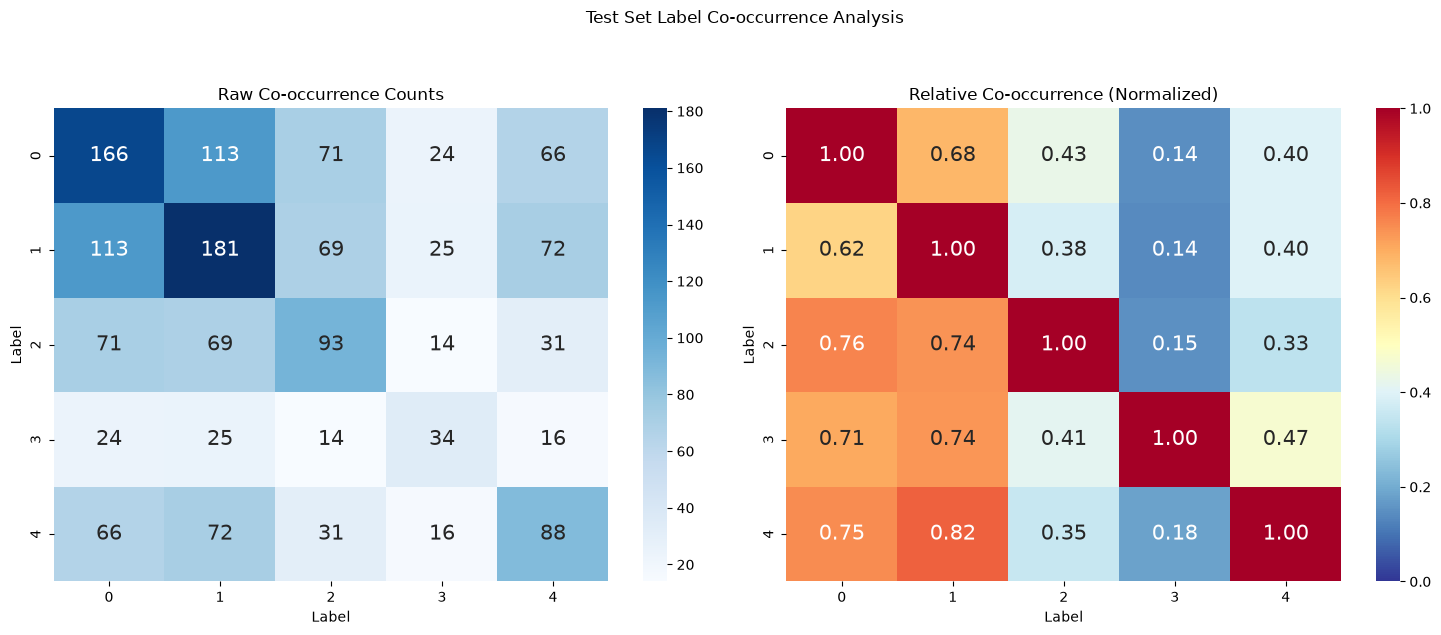


Label Statistics:
Total samples: 300

Label frequencies:
Label 0: 166 samples (55.3%)
Label 1: 181 samples (60.3%)
Label 2: 93 samples (31.0%)
Label 3: 34 samples (11.3%)
Label 4: 88 samples (29.3%)

Most common label combinations:
Combination [0 0 0 0 0]: 52 samples (17.3%)
Combination [0 1 0 0 0]: 34 samples (11.3%)
Combination [1 1 0 0 0]: 28 samples (9.3%)
Combination [1 1 1 0 0]: 25 samples (8.3%)
Combination [1 1 0 0 1]: 24 samples (8.0%)


In [25]:
def plot_label_cooccurrence(
    y, title="Label Co-occurrence Analysis"):
    # I. Compute raw co-occurrence counts:
    cooccurrence = y.T @ y
    # II. Compute relative co-occurrence (normalized by diagonal). Row i divided by how often label i occurs:
    diag = np.diag(cooccurrence)
    relative_cooccurrence = cooccurrence / diag[:, None]

    # III. Create a figure with two subplots:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # IV. Plot raw co-occurrence:
    sns.heatmap(
        cooccurrence, annot=True, fmt='d',
        cmap='Blues', ax=ax1, annot_kws={"fontsize": 15}
    )
    ax1.set_title('Raw Co-occurrence Counts')
    ax1.set_xlabel('Label')
    ax1.set_ylabel('Label')

    # V. Plot relative co-occurrence:
    sns.heatmap(
        relative_cooccurrence, annot=True,
        fmt='.2f', cmap='RdYlBu_r', ax=ax2,
        annot_kws={"fontsize": 15},
        vmin=0, vmax=1
    )
    ax2.set_title('Relative Co-occurrence (Normalized)')
    ax2.set_xlabel('Label')
    ax2.set_ylabel('Label')
    plt.suptitle(title, y=1.05)
    plt.tight_layout()
    plt.show()

    # VI. Print additional statistics:
    print("\nLabel Statistics:")
    print(f"Total samples: {len(y)}")
    print("\nLabel frequencies:")
    for i in range(y.shape[1]):
        count = y[:, i].sum()
        percentage = count / len(y) * 100
        print(f"Label {i}: {count} samples ({percentage:.1f}%)")
    print("\nMost common label combinations:")

    # VII. Get unique combinations and their counts:
    unique_combinations = np.unique(
        y, axis=0, return_counts=True)
    sorted_idx = np.argsort(
        -unique_combinations[1]
    )  # Sort by count (descending)
    for combo, count in zip(
        unique_combinations[0][sorted_idx][:5],
        unique_combinations[1][sorted_idx][:5]
    ):
        percentage = count / len(y) * 100
        print(f"Combination {combo}: "
              f"{count} samples ({percentage:.1f}%)")

plot_label_cooccurrence(
    y_test, "Test Set Label Co-occurrence Analysis")

**Verification against the book:** it prints *Total samples: 300*; label frequencies **166, 181, 93, 34, 88** (55.3 %, 60.3 %, 31.0 %, 11.3 %, 29.3 %); and the top combinations `[0 0 0 0 0]: 52`, `[0 1 0 0 0]: 34`, `[1 1 0 0 0]: 28`, `[1 1 1 0 0]: 25`, `[1 1 0 0 1]: 24` (17.3 %, 11.3 %, 9.3 %, 8.3 %, 8.0 %).
All identical above ✔ (it is a seeded dataset).

How to read the matrices (book): the **raw** matrix cell $(i,j)$ counts samples with both labels (the diagonal = label totals); labels 0 and 1 co-occur most.
The **relative** matrix divides each *row* $i$ by the total of label $i$, so
$$\text{relative}[i,j]=\frac{\#(i\wedge j)}{\#(i)}=P(\text{label } j\mid \text{label } i)$$
> **Book correction.** The book describes the cell as "the percentage of time label *i* occurs when label *j* is present" (and elsewhere "label *i* occurs with label *j*"). With the code as written (division by `diag[:, None]`, i.e. by the *row's* label), the cell is
> **P(j | i)**: "among samples that have label *i*, the share that also have label *j*". The matrix is asymmetric (as the book notes), and reading it the other way round gives the wrong conditional.

Reading examples: a value near 1 in row *i*, column *j* means "whenever *i* is present, *j* almost always is too"; near 0 means they rarely co-occur.

### There's more… (book): other multilabel strategies
Beyond OvR (**binary relevance**), the book names **classifier chains** (each label's classifier also sees the previous labels' predictions, so label dependencies can be exploited). **Extension — a classifier chain on the same data:**

In [26]:
from sklearn.multioutput import ClassifierChain

chain = ClassifierChain(LogisticRegression(solver='liblinear'), order=[0, 1, 2, 3, 4], random_state=2024).fit(X_train, y_train)
y_pred_chain = chain.predict(X_test).astype(int)
cmp = pd.DataFrame({
    "binary relevance (OvR)": [accuracy_score(y_test, y_pred), hamming_loss(y_test, y_pred), f1_score(y_test, y_pred, average="micro")],
    "classifier chain": [accuracy_score(y_test, y_pred_chain), hamming_loss(y_test, y_pred_chain), f1_score(y_test, y_pred_chain, average="micro")],
}, index=["exact-match accuracy", "hamming loss (lower = better)", "micro F1"]).round(3)
cmp

,binary relevance (OvR),classifier chain
exact-match accuracy,0.340,0.413
hamming loss (lower = better),0.209,0.215
micro F1,0.701,0.698


The result is **mixed**: the chain raises the exact-match accuracy noticeably (0.34 → 0.41) — getting whole label *sets* right is exactly what exploiting label dependencies (here labels 0 and 1 co-occur strongly) should help with — but the per-label measures do not improve
(hamming loss 0.209 → 0.215, micro F1 0.701 → 0.698). The gain depends on the data and the label order; it is a tool to try, not a guaranteed improvement. A third classical strategy, the **label powerset**, treats each distinct label combination as one class
(this explodes when there are many labels, but captures every dependency).

### Theory
* **Multiclass vs multilabel:** multiclass = exactly one label from $K$ (mutually exclusive); multilabel = any subset of $K$ labels (a binary indicator vector). Do not confuse the two: softmax suits the first, $K$ independent sigmoids the second.
* **Binary relevance:** $K$ independent classifiers; simple, scalable, ignores label dependencies. **Classifier chains:** models dependencies via chaining. **Label powerset:** reduces to multiclass over combinations.
* **Metrics:** per-label precision/recall/F1 and their micro/macro/weighted/samples averages; **hamming loss** (fraction of wrong label decisions); **subset accuracy** (exact match — strict); Jaccard score.
* **Imbalance:** rare labels (label 3 is present in 11 % of samples) get low recall; micro averages are dominated by frequent labels, macro averages expose rare ones.

### Hands-on workflow (from the book)
Generate data with `make_multilabel_classification` → check for missing values (none) → fit one logistic regression per label → predict → accuracy and the classification report → heat-maps to understand label relationships (done above).

## 5. Model evaluation metrics

**Summary.** The same metrics as Chapter 4 (accuracy, precision, recall, F1), plus the **ROC curve** and **AUC**, applied to a logistic regression with the `liblinear` solver on the Breast Cancer data (70/30 split).

### Getting ready

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    precision_score, recall_score,
    f1_score, roc_curve, auc
)
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt

data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

### How to do it…

In [28]:
model = LogisticRegression(solver='liblinear')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]      # probability of class 1 (benign)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
report = classification_report(y_test, y_pred)

print(f"Accuracy {accuracy:.2f}")
print(f"Precision {precision:.2f}")
print(f"Recall {recall:.2f}")
print(f"F1 Score {f1:.2f}")
print(f"ROC AUC {roc_auc:.2f}")
print("Classification Report")
print(report)

Accuracy 0.94
Precision 0.94
Recall 0.95
F1 Score 0.95
ROC AUC 0.99
Classification Report
              precision    recall  f1-score   support

           0       0.92      0.91      0.92        67
           1       0.94      0.95      0.95       104

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



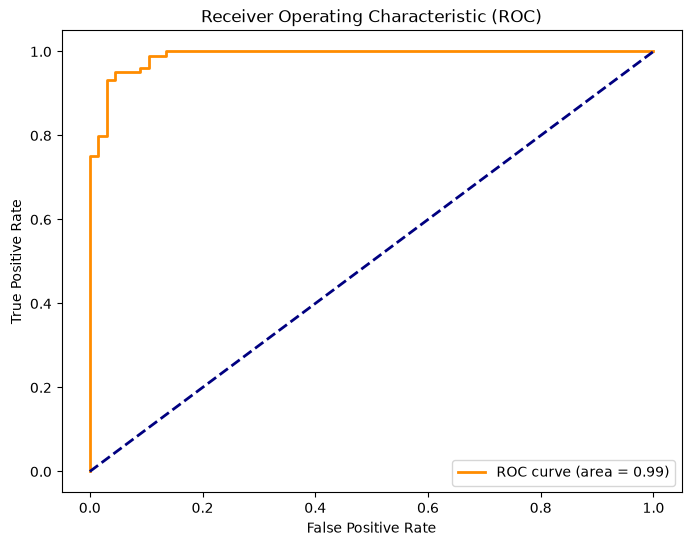

In [29]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy',
         lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Verification against the book:** it prints `Accuracy 0.94`, `Precision 0.94`, `Recall 0.95`, `F1 Score 0.95`, `ROC AUC 0.99` — all reproduced above ✔; the ROC curve hugs the top-left corner (AUC 0.99), "fairly solid performance".

> **Note on the positive class.** `precision_score`/`recall_score`/`roc_curve` use **class 1 as positive**, which in this dataset is **benign**. So "recall 0.95" is the share of *benign* tumours recognised, not the share of cancers caught. For cancer screening you would
> treat *malignant* as the positive class — compute those numbers below.

### How it works…
* **Accuracy** — overall correctness. **Precision** $=\frac{TP}{TP+FP}$ — of the predicted positives, how many are right. **Recall** $=\frac{TP}{TP+FN}$ — of the actual positives, how many are found. **F1** $=\frac{2PR}{P+R}$ — harmonic mean.
* **ROC curve** — true-positive rate ($TPR$ = recall) against false-positive rate ($FPR=\frac{FP}{FP+TN}$) as the **decision threshold** sweeps from 1 to 0; the dashed diagonal is a random classifier.
* **AUC** — area under the ROC curve: 0.5 = random, 1 = perfect ranking. It summarises discrimination across *all* thresholds.

**Extension — what the AUC means, verified by brute force, and what each threshold does:**

In [30]:
pos, neg = y_prob[y_test == 1], y_prob[y_test == 0]
pairs = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()
print(f"AUC = {roc_auc:.4f} | P(random benign case scores higher than a random malignant case) = {pairs:.4f}  (the same number)")

rows = []
for t in (0.3, 0.5, 0.7, 0.9, 0.95):
    pred_t = (y_prob >= t).astype(int)
    rows.append({"threshold on P(benign)": t, "malignant recall (sensitivity)": recall_score(y_test, pred_t, pos_label=0),
                 "malignant precision": precision_score(y_test, pred_t, pos_label=0, zero_division=0),
                 "malignant missed (FN)": int(((y_test == 0) & (pred_t == 1)).sum()), "benign flagged as malignant (FP)": int(((y_test == 1) & (pred_t == 0)).sum()),
                 "accuracy": accuracy_score(y_test, pred_t)})
pd.DataFrame(rows).set_index("threshold on P(benign)").round(3)

AUC = 0.9892 | P(random benign case scores higher than a random malignant case) = 0.9892  (the same number)


,malignant recall (sensitivity),malignant precision,malignant missed (FN),benign flagged as malignant (FP),accuracy
threshold on P(benign),,,,,
0.30,0.881,0.983,8,1,0.947
0.50,0.910,0.924,6,5,0.936
0.70,0.955,0.901,3,7,0.942
0.90,0.970,0.774,2,19,0.877
0.95,0.985,0.725,1,25,0.848


Raising the threshold on $P(\text{benign})$ makes the model call fewer tumours benign: **malignant recall rises** (from 0.88 at 0.3 to 0.985 at 0.95: missed cancers fall from 8 to 1) while more benign tumours are flagged. Accuracy barely moves up to 0.7 (0.94–0.95)
but then falls sharply (0.88 at 0.9, 0.85 at 0.95) because precision on the malignant class collapses (0.98 → 0.73) — pushing the threshold to the extreme buys a few more caught cancers at the cost of many false alarms. Which threshold to use is a **cost decision**, not a statistical one —
and the ROC curve shows all these trade-offs at once. (The same logic is why the book says: "in situations where false positives are costly, precision may be more important; where it's important to capture as many positives as possible, recall.")

**Extension — the ROC curve with *malignant* as the positive class** (flip the score; the AUC is identical, only the labelling changes):

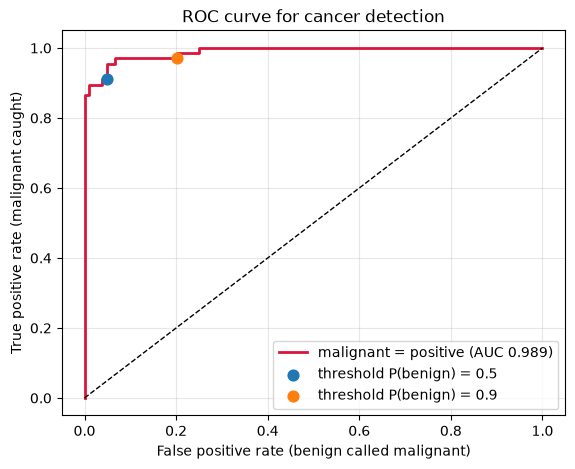

In [31]:
fpr_m, tpr_m, thr_m = roc_curve(y_test, 1 - y_prob, pos_label=0)
plt.figure(figsize=(6.5, 5))
plt.plot(fpr_m, tpr_m, c="crimson", lw=2, label=f"malignant = positive (AUC {auc(fpr_m, tpr_m):.3f})")
for t in (0.5, 0.9):
    i = np.argmin(np.abs((1 - thr_m) - t)); plt.scatter(fpr_m[i], tpr_m[i], s=60, zorder=3, label=f"threshold P(benign) = {t}")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("False positive rate (benign called malignant)"); plt.ylabel("True positive rate (malignant caught)")
plt.title("ROC curve for cancer detection"); plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.show()

### Visualizing model performance (book) and There's more…
The ROC curve visualises the trade-off between true- and false-positive rates; the AUC is a single threshold-free summary — higher is better. The choice of metric depends on the goal and the data. **Caveat** (Chapter 4's imbalance discussion): with *very* imbalanced classes,
ROC-AUC can look optimistic and **precision–recall curves / average precision** are more informative.

### Theory
* **Threshold-dependent vs threshold-free metrics:** accuracy, precision, recall and F1 describe a model *at one threshold*; ROC-AUC (and PR-AUC) describe the *ranking quality* across all thresholds.
* **ROC-AUC is invariant to class balance in the data, precision is not:** precision depends on the prevalence of the positive class, which is why a model that looks great by AUC can still have poor precision on rare events.
* **Probabilities vs labels:** `predict_proba` carries more information than `predict`; use it to set an application-specific threshold. Whether the probabilities are *calibrated* (a predicted 0.8 really means 80 %) is a separate property, checked with calibration curves.
* **Choose the metric from the costs:** screening (miss = costly) → recall; spam filter (false alarm = costly) → precision; balanced overall → F1/accuracy; ranking → AUC.

### Hands-on workflow (from the book)
Load Breast Cancer → `LogisticRegression` → `fit` → `predict` and `predict_proba` → accuracy, precision, recall, F1, ROC-AUC → plot the ROC curve (done above).

## 6. Practical exercises with advanced logistic regression

The book lists three exercises as step lists (solutions are in its repository). Here is my implementation of each.

### Exercise 1 — Build a regularized logistic regression (Lasso and Ridge) on Breast Cancer
Steps: libraries → data → split → create and train a **Lasso** model → predict → evaluate (the book also names Ridge in the introduction, so both are compared, with `C` chosen by cross-validation instead of fixed).

In [32]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

Xb, yb = load_breast_cancer(return_X_y=True)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=2024, stratify=yb)

results, fitted = {}, {}
for name, pen in (("Lasso (L1)", "l1"), ("Ridge (L2)", "l2")):
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(solver="liblinear", max_iter=5000))])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                         # 'penalty' is deprecated since 1.8 but still works (see Section 3)
        pipe.set_params(clf__penalty=pen)
        gs = GridSearchCV(pipe, {"clf__C": np.logspace(-3, 2, 20)}, cv=5, scoring="accuracy").fit(Xb_tr, yb_tr)
    best = gs.best_estimator_; pred = best.predict(Xb_te); fitted[name] = best
    results[name] = {"best C": gs.best_params_["clf__C"], "CV accuracy": gs.best_score_, "test accuracy": accuracy_score(yb_te, pred),
                     "malignant recall": recall_score(yb_te, pred, pos_label=0), "non-zero coefs": int((best[-1].coef_ != 0).sum())}
display(pd.DataFrame(results).T.round(3))
print("Classification report of the tuned Lasso model:")
print(classification_report(yb_te, fitted["Lasso (L1)"].predict(Xb_te), target_names=load_breast_cancer().target_names))

,best C,CV accuracy,test accuracy,malignant recall,non-zero coefs
Lasso (L1),0.428,0.980,0.965,0.969,10.0
Ridge (L2),0.428,0.985,0.971,0.953,30.0


Classification report of the tuned Lasso model:
              precision    recall  f1-score   support

   malignant       0.94      0.97      0.95        64
      benign       0.98      0.96      0.97       107

    accuracy                           0.96       171
   macro avg       0.96      0.97      0.96       171
weighted avg       0.97      0.96      0.97       171



With `C` chosen by cross-validation (both pick `C ≈ 0.43`), the regularised models reach 96.5 % (L1) and 97.1 % (L2) test accuracy and 98.0 % / 98.5 % CV accuracy; the L1 model keeps 10 of the 30 features (a much sparser, more interpretable model), the L2 model keeps all 30.
The accuracy gap is 1 test sample out of 171 — within noise — so choose by sparsity needs and by the cross-validated score, not by a single split. (The tuned L1 model also has the higher malignant recall here, 0.969 vs 0.953, again a difference of one case.)

### Exercise 2 — Evaluate multiclass (multinomial) logistic regression on Iris
Steps: libraries → data → split → create and train a multinomial model → predict → evaluate.

accuracy: 0.9556
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.93      0.93      0.93        15
   virginica       0.93      0.93      0.93        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



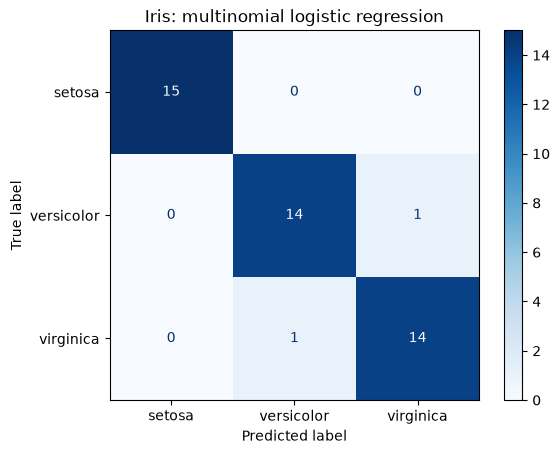

5-fold CV accuracy: [0.967 0.933 0.967 1.    0.933]


In [33]:
from sklearn.metrics import ConfusionMatrixDisplay

Xi, yi = load_iris(return_X_y=True)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, random_state=2024, stratify=yi)

multi = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]).fit(Xi_tr, yi_tr)    # multinomial by default
pred = multi.predict(Xi_te)
print("accuracy:", round(accuracy_score(yi_te, pred), 4))
print(classification_report(yi_te, pred, target_names=load_iris().target_names))
ConfusionMatrixDisplay.from_predictions(yi_te, pred, display_labels=load_iris().target_names, cmap="Blues"); plt.title("Iris: multinomial logistic regression"); plt.show()

print("5-fold CV accuracy:", cross_val_score(Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]), Xi, yi, cv=StratifiedKFold(5, shuffle=True, random_state=2024)).round(3))

Setosa is classified perfectly; the few errors are versicolor ↔ virginica, the overlapping pair seen in the pairplot. Cross-validation (5 folds) gives a more reliable estimate (≈ 0.95–0.97) than the single 45-sample test set.

### Exercise 3 — Visualise the decision boundary of a logistic regression on synthetic data
Steps: libraries → synthetic binary dataset → split → train → **mesh grid** → predict class probabilities across the grid → plot decision boundaries.

test accuracy: 0.987 | coefficients: [-0.45  4.4 ] intercept: [1.44]


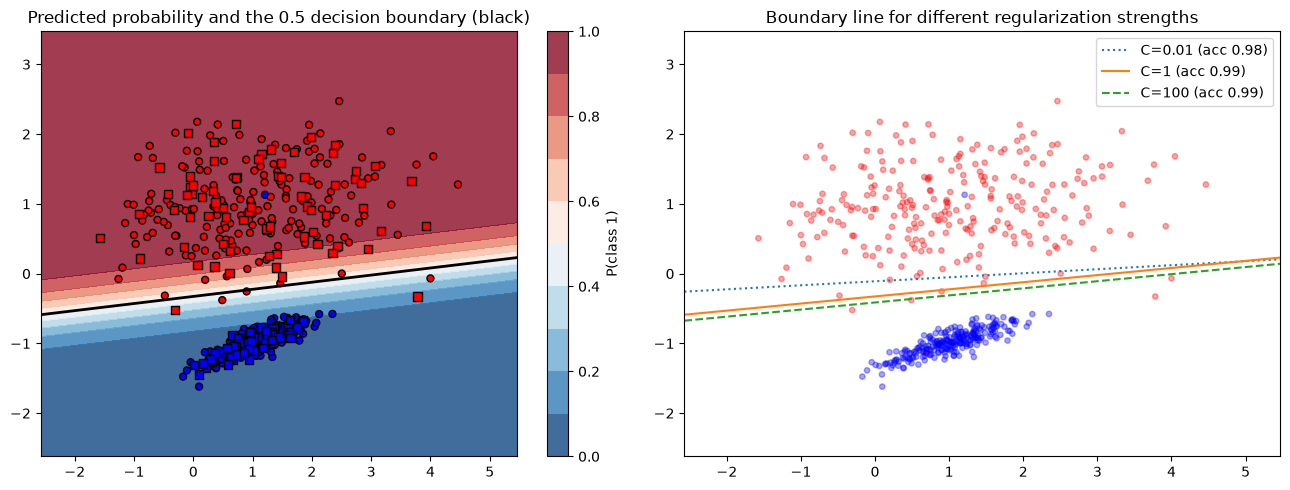

In [34]:
from sklearn.datasets import make_classification

Xs, ys = make_classification(n_samples=500, n_features=2, n_redundant=0, n_informative=2, n_clusters_per_class=1, class_sep=1.0, flip_y=0.03, random_state=2024)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=2024)

clf = LogisticRegression().fit(Xs_tr, ys_tr)
print("test accuracy:", round(clf.score(Xs_te, ys_te), 3), "| coefficients:", clf.coef_[0].round(2), "intercept:", clf.intercept_.round(2))

# mesh grid over the feature space, and class-1 probability at every grid point
xx, yy = np.meshgrid(np.linspace(Xs[:, 0].min() - 1, Xs[:, 0].max() + 1, 300), np.linspace(Xs[:, 1].min() - 1, Xs[:, 1].max() + 1, 300))
proba = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cs = ax[0].contourf(xx, yy, proba, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=.8)
ax[0].contour(xx, yy, proba, levels=[0.5], colors="k", linewidths=2)
ax[0].scatter(Xs_tr[:, 0], Xs_tr[:, 1], c=ys_tr, cmap="bwr", edgecolor="k", s=25); ax[0].scatter(Xs_te[:, 0], Xs_te[:, 1], c=ys_te, cmap="bwr", edgecolor="k", marker="s", s=35)
fig.colorbar(cs, ax=ax[0], label="P(class 1)"); ax[0].set_title("Predicted probability and the 0.5 decision boundary (black)")
for C, ls in ((0.01, ":"), (1, "-"), (100, "--")):                              # effect of regularization strength on the boundary
    m = LogisticRegression(C=C).fit(Xs_tr, ys_tr)
    w, b = m.coef_[0], m.intercept_[0]; xs_line = np.array([xx.min(), xx.max()])
    ax[1].plot(xs_line, -(w[0] * xs_line + b) / w[1], ls, label=f"C={C} (acc {m.score(Xs_te, ys_te):.2f})")
ax[1].scatter(Xs[:, 0], Xs[:, 1], c=ys, cmap="bwr", alpha=.35, s=15); ax[1].set_xlim(xx.min(), xx.max()); ax[1].set_ylim(yy.min(), yy.max())
ax[1].set_title("Boundary line for different regularization strengths"); ax[1].legend()
plt.tight_layout(); plt.show()

The **black line** is where $P(\text{class }1)=0.5$ — a straight line, because the logit is linear in the features; the colour shows how confidence grows away from it (the probability changes along a sigmoid, fastest near the line). Points near it are the uncertain ones.
On the right, the boundary line for `C=1` and `C=100` nearly coincide (accuracy 0.99 for both), while the strongly regularised `C=0.01` line is visibly shifted and flatter (accuracy 0.98): strong regularisation shrinks the coefficients — making the probabilities less extreme, i.e. a wider transition zone — and
also pulls the intercept towards 0, which moves the line. For well separated classes like these the effect on accuracy is small.

### Theory (for the exercises)
* **Regularised models are selected by cross-validation over `C`** (inverse strength); L1 for sparsity, L2 for stability; scale inside a pipeline.
* **For multiclass evaluation** read the confusion matrix, not just accuracy: it shows *which* classes are confused.
* **Decision boundary of logistic regression is always linear** (in the original features); a curved boundary requires added features (e.g. `PolynomialFeatures`) or a different model.

## Chapter takeaways
1. **Logistic regression** models the probability $P(Y=1\mid x)=\sigma(\beta_0+\beta^\top x)$; coefficients are fitted by maximum likelihood (minimising log-loss) and are interpretable as changes in **log-odds** (odds ratios $e^{\beta}$).
2. **Multiclass:** OvR trains one binary model per class; **multinomial (softmax)** is the joint model and the modern default. In current scikit-learn use the default for multinomial and `OneVsRestClassifier` for OvR.
3. **Regularization:** `C` is the *inverse* strength. L2 shrinks, L1 selects features (7 of 30 survive at `C=0.1`); choose `C` by cross-validation and scale features first. Use `l1_ratio` instead of the deprecated `penalty`.
4. **Multilabel** = several labels per sample; binary relevance (one classifier per label) is the baseline; classifier chains exploit label dependencies; use hamming loss and per-label/averaged metrics, not only exact-match accuracy.
5. **Evaluation:** accuracy hides what matters; use precision, recall, F1 per class, the ROC curve and AUC (threshold-free ranking quality), and choose the threshold from the **cost of errors** — for cancer screening, malignant recall.
6. **Always check which class is "positive"** and which averaging (macro/weighted/micro) a metric uses before comparing numbers.

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| Sigmoid formula | exponent ends in $\beta_n + X_n$ | should be the product $\beta_nX_n$ |
| Multiclass code | `multi_class='multinomial'` and `LogisticRegression(solver='liblinear')` for OvR | both fail on current scikit-learn (`multi_class` removed; `liblinear` is binary-only). Use the default (multinomial) and `OneVsRestClassifier(...)` for OvR — reproduces the book's 0.956 / 0.933 |
| "Macro accuracy" | "label-wise unweighted average" | macro *average of precision/recall/F1*; the report has no macro accuracy |
| Multinomial text | "multinomial classification for a binary problem" | Iris has three classes |
| Petal features | "high kurtosis (peaked)" confirms their value | excess kurtosis is about −1.4 / −1.3 (flat, bimodal); their value comes from class separation |
| Regularization code | `penalty='l1'/'l2'` | deprecated since scikit-learn 1.8 (removal in 1.10); use `l1_ratio=1/0` |
| Ridge vs Lasso conclusion | "ridge better in precision, Lasso in recall" | true only for class 0 (malignant); reversed for class 1; overall Ridge is better here |
| Co-occurrence function | missing comma after `annot_kws=...` before `vmin=0` | `SyntaxError` as printed; comma added |
| Relative co-occurrence | cell = "% of time label *i* occurs when label *j* is present" | with the code as written the cell is P(*j* \| *i*) (row-normalised) |
| Positive class | metrics shown without saying class 1 = benign | for cancer detection, report malignant (class 0) recall |
| Imports | `plt`, `sns`, `display` not imported in the snippets | added |

*Next: Chapter 7 — Support Vector Machines and Kernel Methods.*